**Chiller Digital Twin 4: Operating Optimization and Part Load**

Besides keeping the condenser clean, the operator can save energy through the way the chiller is run:

* **(a) Chilled water setpoint reset**: a warmer chilled water supply raises the evaporating pressure and the COP. Each degree is worth a few percent of compressor power.
* **(b) Cooling water flow**: more cooling water lowers the condensing pressure and the compressor power, but the cooling water pump uses more power ($P \propto Q^3$ by the affinity laws). We find the flow that minimizes the **total** power with an IDAES/Pyomo optimization. The pump is assumed to use 0.26 kW at the design flow (15 m of head, 70 % efficiency).
* **(c) Part load map**: COP vs cooling load and cooling water temperature, for a clean and a fouled condenser.

All cases hold the cooling load (chilled water flow and temperature drop) and the 7 °C supply unless stated. The compressor isentropic efficiency is kept constant at 75 %, a simplification: real compressors lose efficiency at part load, so the part load COPs here are optimistic.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


In [2]:
from chiller import setup_chiller_model, chiller_results

# Build, initialize and solve the chiller at its design point
model, results = setup_chiller_model()
print(results.solver.termination_condition)
cop_clean = chiller_results(model)["COP"]
print("Design COP: {0:.3f}".format(cop_clean))

The DOF is 0
optimal
Design COP: 4.563


## (a) Chilled water setpoint reset

In [3]:
from chiller_case_studies import setpoint_reset_study

setpoint = setpoint_reset_study(model, supplies=(7, 8, 9, 10, 6))
setpoint[["Evaporator pressure (bar)", "Cooling duty (kW)", "Compressor power (kW)", "COP"]]

,Evaporator pressure (bar),Cooling duty (kW),Compressor power (kW),COP
Chilled water supply setpoint (C),,,,
6,3.035778,20.989404,4.759032,4.410435
7,3.146606,20.980594,4.602629,4.558393
8,3.260496,20.972438,4.448895,4.714078
9,3.377505,20.964894,4.297751,4.878108
10,3.497689,20.957922,4.149124,5.051168


## (b) Cooling water flow

In [4]:
from chiller_case_studies import cooling_water_flow_study, optimize_cooling_water_flow

cw = cooling_water_flow_study(model, [0.8, 1.0, 1.22, 1.6, 2.0, 2.5])
best = optimize_cooling_water_flow(model)
print("Optimal cooling water flow: {0:.3f} kg/s, total power {1:.3f} kW".format(
    best["Optimal cooling water flow (kg/s)"], best["Total power (kW)"]))
cw[["Condenser pressure (bar)", "Compressor power (kW)", "Pump power (kW)", "Total power (kW)", "COP"]]

Optimal cooling water flow: 0.929 kg/s, total power 4.797 kW


,Condenser pressure (bar),Compressor power (kW),Pump power (kW),Total power (kW),COP
Cooling water flow (kg/s),,,,,
0.80,10.416081,4.738664,0.073310,4.811974,4.427534
1.00,10.269361,4.657778,0.143184,4.800962,4.504421
1.22,10.169529,4.602629,0.260000,4.862629,4.558393
1.60,10.067115,4.545954,0.586481,5.132435,4.615224
2.00,10.004170,4.511068,1.145470,5.656538,4.650915
2.50,9.955346,4.483980,2.237247,6.721227,4.679011


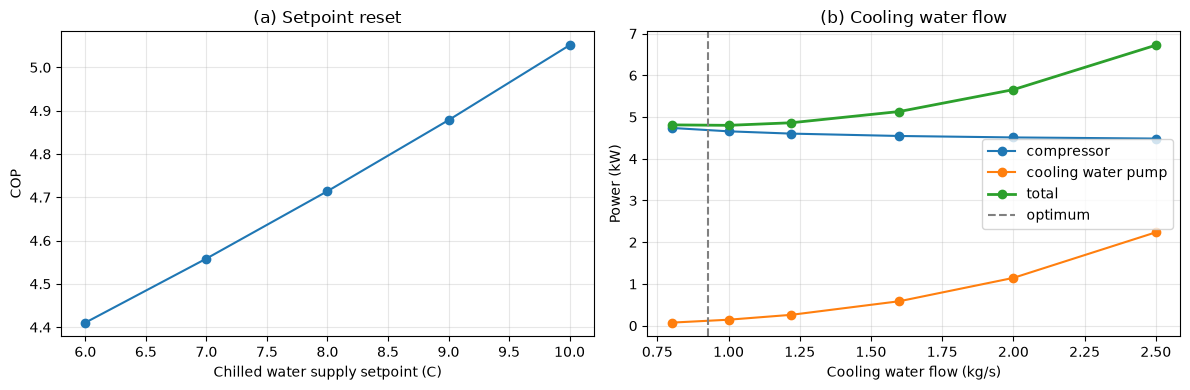

In [5]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(setpoint.index, setpoint["COP"], "o-")
ax1.set_xlabel("Chilled water supply setpoint (C)")
ax1.set_ylabel("COP")
ax1.set_title("(a) Setpoint reset")
ax1.grid(alpha=0.3)
ax2.plot(cw.index, cw["Compressor power (kW)"], "o-", label="compressor")
ax2.plot(cw.index, cw["Pump power (kW)"], "o-", label="cooling water pump")
ax2.plot(cw.index, cw["Total power (kW)"], "o-", label="total", linewidth=2)
ax2.axvline(best["Optimal cooling water flow (kg/s)"], color="grey", linestyle="--", label="optimum")
ax2.set_xlabel("Cooling water flow (kg/s)")
ax2.set_ylabel("Power (kW)")
ax2.set_title("(b) Cooling water flow")
ax2.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()

## (c) Part load map

In [6]:
import pandas as pd
from chiller_case_studies import part_load_map

clean = part_load_map(model, fouling=0.0)
fouled = part_load_map(model, fouling=0.00035)
print("COP, clean condenser")
display(clean.pivot(index="Load (%)", columns="Cooling water inlet (C)", values="COP"))
print("COP, fouled condenser (Rf = 0.00035 m2K/W)")
display(fouled.pivot(index="Load (%)", columns="Cooling water inlet (C)", values="COP"))

COP, clean condenser


Cooling water inlet (C),26,30,34
Load (%),,,
25.0,7.149442,6.066970,5.231704
50.0,6.741041,5.765956,4.999610
75.0,5.984543,5.173289,4.519873
100.0,5.227895,4.558393,4.006683


COP, fouled condenser (Rf = 0.00035 m2K/W)


Cooling water inlet (C),26,30,34
Load (%),,,
25.0,7.068172,6.009593,5.189003
50.0,6.341396,5.455416,4.749685
75.0,5.386746,4.686957,4.113116
100.0,4.526913,3.968901,3.499154


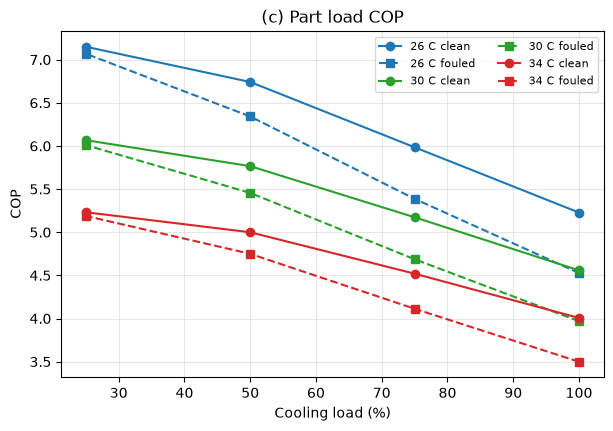

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for Tcw, color in zip((26, 30, 34), ("tab:blue", "tab:green", "tab:red")):
    c = clean[clean["Cooling water inlet (C)"] == Tcw]
    f = fouled[fouled["Cooling water inlet (C)"] == Tcw]
    ax.plot(c["Load (%)"], c["COP"], "o-", color=color, label="{0} C clean".format(Tcw))
    ax.plot(f["Load (%)"], f["COP"], "s--", color=color, label="{0} C fouled".format(Tcw))
ax.set_xlabel("Cooling load (%)")
ax.set_ylabel("COP")
ax.set_title("(c) Part load COP")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
plt.show()